# 05 - Winter outlook: is gas a good opportunity?

Notebooks 03-04 showed that trading the Thursday report isn't a retail edge. A retail trader's advantage is **patience**: picking moments when the risk is lopsided, and holding for weeks rather than minutes.

This notebook builds that kind of view:

1. **Fix the forecast:** heating demand only kicks in once it's properly cold (the kink in chart 08).
2. **Project end-of-winter storage** (end of March) under every past winter's weather. A mild winter leaves a lot of gas, a cold one very little.
3. **Turn storage into a signal with thresholds:**
   - Projected end-March storage **> 10% below normal = Tight**: upside spike risk.
   - **Within ±10% = Normal**: weather decides, no edge.
   - **> 10% above normal = Loose**: prices tend to stay near the floor.
4. **Check whether the price already reflects it.** Is today's price cheap, fair or expensive compared with past prices in the same storage state?
5. **Backtest the rule on every past winter** to measure how accurate it would have been.

**Not financial advice.** This is a framework for thinking about risk, and section 5 shows its limits.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from gasdata import expiry_and_roll_days, rolling_forecast
from style import BAND, BLUE, GRAY, INK2, ORANGE, RED  # shared project chart style

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
START = "2015-01-01"
WINDOW = 156  # weeks of history for each model fit (3 years)
TIGHT, LOOSE = -10, 10  # thresholds on projected end-March storage vs 5-year average (%)

storage = pd.read_csv(DATA_DIR / "storage_features.csv", index_col="period", parse_dates=["period", "report_date"])
prices = pd.read_csv(DATA_DIR / "prices_daily.csv", index_col="Date", parse_dates=True)
weekly_dd = pd.read_csv(DATA_DIR / "degree_days_daily.csv", index_col=0, parse_dates=True).resample("W-FRI").sum()


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


## 1. Fixing the forecast: heating only starts when it's cold
Chart 08 shows that storage change barely responds to the first ~50 HDD per week, then falls steeply. In mild weather, heating is mostly off. A straight line therefore overstates the effect of the first cold weeks of autumn.

The fix splits HDD into two parts with separate slopes:
- `hdd_low` = HDD up to a kink point K
- `hdd_high` = HDD above K

The code tries several values of K and keeps the one with the smallest out-of-sample miss. Choosing K on the test period is a mild form of fitting to the data, but it's a single number and the improvement turns out to be similar across nearby values.

In [2]:
def weather_features(weekly, kink):
    out = weekly.copy()
    out["hdd_low"] = out["hdd"].clip(upper=kink)
    out["hdd_high"] = (out["hdd"] - kink).clip(lower=0)
    return out


def week_on_week_errors(x_cols, kink=50):
    d = storage.join(weather_features(weekly_dd, kink), how="inner")
    d["prev_change"] = d["change_bcf"].shift(1)
    d["d_change"] = d["change_bcf"] - d["prev_change"]
    for c in ["hdd", "hdd_low", "hdd_high", "cdd"]:
        d[f"d_{c}"] = d[c].diff()
    forecast = d["prev_change"] + rolling_forecast(d, "d_change", x_cols, WINDOW)
    return (d["change_bcf"] - forecast).loc[START:]


baseline = week_on_week_errors(["d_hdd", "d_cdd"])
mae = {"No kink (notebook 04)": baseline.abs().mean()}
for k in [30, 40, 50, 60, 70, 80]:
    mae[f"Kink at {k} HDD/week"] = week_on_week_errors(["d_hdd_low", "d_hdd_high", "d_cdd"], k).abs().mean()
mae = pd.Series(mae).round(2)
HDD_KINK = int(mae.drop("No kink (notebook 04)").idxmin().split()[2])

best_err = week_on_week_errors(["d_hdd_low", "d_hdd_high", "d_cdd"], HDD_KINK)
print(mae.to_string())
print(f"\nChosen kink: {HDD_KINK} HDD/week")
print(f"Week ending {best_err.index[-1].date()}: miss {baseline.iloc[-1]:+.0f} Bcf without kink -> {best_err.iloc[-1]:+.0f} Bcf with kink")

No kink (notebook 04)    17.07
Kink at 30 HDD/week      16.46
Kink at 40 HDD/week      16.05
Kink at 50 HDD/week      15.68
Kink at 60 HDD/week      15.40
Kink at 70 HDD/week      15.28
Kink at 80 HDD/week      15.30

Chosen kink: 70 HDD/week
Week ending 2026-10-23: miss +56 Bcf without kink -> +20 Bcf with kink


## 2. Projecting storage to the end of winter
The week-on-week model is good for next week's number but drifts over 20+ weeks, because small errors pile up. For a season-long projection, the code uses the method analysts typically use, **normal path + weather anomaly**:

> projected weekly change = **5-year average change for that week** + sensitivity × (**this week's weather − normal weather**) + balance adjustment

- **5-year average path:** already contains the normal seasonal shape, including holiday weeks.
- **Weather anomaly:** HDD and CDD minus their 5-year average for the same week. The sensitivities (Bcf per degree day) are fitted on the last 3 years. Under normal weather the anomaly is zero, and the projection simply follows the 5-year path.
- **Balance adjustment:** the model's average miss over the last 8 weeks, at **half weight**. If injections have recently been lower than weather explains, the market is tighter than normal, for example because of higher LNG exports or lower production. That usually persists, but only partly.

I tried several variants (window length, balance weeks and weight) on 11 past winters and kept the best. With only 11 winters, the accuracy figures below are therefore slightly flattering.

**Weather scenarios:**
- **Normal weather:** zero anomaly.
- **Analog years:** replay each past winter's actual weather, 2010/11 onwards. This gives about 16 plausible winters, from mild to severe.

In [3]:
wx = weather_features(weekly_dd, HDD_KINK)
df = storage.join(wx, how="inner")
FEATURES = ["hdd_low", "hdd_high", "cdd"]
BALANCE_WEEKS, BALANCE_WEIGHT = 8, 0.5


def iso_key(d):
    iso = d.isocalendar()
    return iso.year, min(iso.week, 52)  # fold rare week 53 into 52


def by_iso(data):
    out = data.copy()
    out.index = pd.MultiIndex.from_tuples([iso_key(d) for d in data.index])
    return out[~out.index.duplicated()]


wx_by_iso, chg_by_iso, lvl_by_iso = by_iso(wx[FEATURES]), by_iso(df["change_bcf"]), by_iso(df["storage_bcf"])


def normal_5y(table, d, years=5):
    """Average of `table` for the same ISO week over the previous 5 years (NaN if history is missing)."""
    y, w = iso_key(d)
    vals = [table.loc[(y - k, w)] for k in range(1, years + 1) if (y - k, w) in table.index]
    if len(vals) < years:
        return pd.Series(np.nan, index=table.columns) if isinstance(table, pd.DataFrame) else np.nan
    return pd.concat(vals, axis=1).mean(axis=1) if isinstance(table, pd.DataFrame) else float(np.mean(vals))


# Historical anomalies: weather and storage change vs their own 5-year normal
normal_wx_hist = pd.DataFrame([normal_5y(wx_by_iso, d) for d in df.index], index=df.index)
wx_anom = df[FEATURES] - normal_wx_hist
chg_anom = df["change_bcf"] - pd.Series([normal_5y(chg_by_iso, d) for d in df.index], index=df.index)


def fit_sensitivity(asof):
    """Bcf per degree-day anomaly (fitted on the 3 years to `asof`) and the half-weighted recent balance."""
    idx = df.loc[:asof].index[-WINDOW:]
    X, Y = wx_anom.loc[idx].to_numpy(float), chg_anom.loc[idx].to_numpy(float)
    ok = ~np.isnan(X).any(axis=1) & ~np.isnan(Y)
    beta = np.linalg.lstsq(X[ok], Y[ok], rcond=None)[0]  # no intercept: normal weather -> normal change
    resid = pd.Series(Y - X @ beta, index=idx)
    return beta, resid.iloc[-BALANCE_WEEKS:].mean() * BALANCE_WEIGHT


def season_end(asof):
    """Last Friday of March at the end of the current winter."""
    year = asof.year + 1 if asof.month >= 4 else asof.year
    d = pd.Timestamp(f"{year}-03-31")
    return d - pd.Timedelta(days=(d.weekday() - 4) % 7)


def future_weeks(asof):
    return pd.date_range(asof + pd.Timedelta(days=7), season_end(asof), freq="W-FRI")


def project_path(asof, weeks, beta, adj, weather=None):
    """Storage path from `asof` over `weeks`; weather=None means normal weather (zero anomaly)."""
    normal_chg = np.array([normal_5y(chg_by_iso, d) for d in weeks])
    if weather is None:
        anomaly = np.zeros((len(weeks), len(FEATURES)))
    else:
        normal_wx = pd.DataFrame([normal_5y(wx_by_iso, d) for d in weeks], index=weeks)
        anomaly = (weather[FEATURES] - normal_wx).to_numpy(float)
    return df.loc[asof, "storage_bcf"] + np.cumsum(normal_chg + anomaly @ beta + adj)


def analog_weather(weeks, k):
    """The weather of the same weeks k years earlier (None if not available)."""
    keys = [(iso_key(d)[0] - k, iso_key(d)[1]) for d in weeks]
    if not all(key in wx_by_iso.index for key in keys):
        return None
    return pd.DataFrame([wx_by_iso.loc[key] for key in keys], index=weeks)


def normal_level(d):
    return normal_5y(lvl_by_iso, d)


def deviation_pct(level, d):
    return (level - normal_level(d)) / normal_level(d) * 100

### How accurate is the projection?
Before trusting the projection, test it. For each past winter, stand at the **last October report** and project end-of-March storage two ways:
- **With the weather that actually happened.** This measures the model's own error, the part we could improve.
- **With normal weather.** This is what you'd actually know on the day. The extra error is weather you can't know in advance.

Compare both errors with the **±10% threshold (about 180 Bcf)**. If the error is about as large as the threshold, the Tight/Normal/Loose call is uncertain whenever the projection lands near a boundary.

In [4]:
rows = []
for year in range(2015, storage.index[-1].year):
    oct_weeks = df.loc[f"{year}-10-01":f"{year}-10-31"].index
    if len(oct_weeks) == 0:
        continue
    asof = oct_weeks[-1]
    end = season_end(asof)
    if end not in df.index:
        continue
    weeks = future_weeks(asof)
    beta, adj = fit_sensitivity(asof)
    actual_end = df.loc[end, "storage_bcf"]
    rows.append({
        "winter": f"{year}/{str(year + 1)[2:]}",
        "actual_end_bcf": actual_end,
        "error_actual_weather": project_path(asof, weeks, beta, adj, wx.loc[weeks])[-1] - actual_end,
        "error_normal_weather": project_path(asof, weeks, beta, adj)[-1] - actual_end,
    })
proj_test = pd.DataFrame(rows).set_index("winter")
print(proj_test.round(0).to_string())
print(f"\nAverage absolute error, actual weather: {proj_test['error_actual_weather'].abs().mean():.0f} Bcf")
print(f"Average absolute error, normal weather: {proj_test['error_normal_weather'].abs().mean():.0f} Bcf")
print(f"For scale: the ±10% threshold is about {0.1 * normal_level(season_end(df.index[-1])):.0f} Bcf")

         actual_end_bcf  error_actual_weather  error_normal_weather
winter                                                             
2015/16            2468                 239.0                -707.0
2016/17            2051                 205.0                -238.0
2017/18            1354                 292.0                 237.0
2018/19            1130                -328.0                -123.0
2019/20            1986                 246.0                 -17.0
2020/21            1764                 -51.0                 -85.0
2021/22            1415                 263.0                 216.0
2022/23            1830                 -35.0                -211.0
2023/24            2259                 -24.0                -473.0
2024/25            1773                -157.0                  28.0
2025/26            1851                 -79.0                 100.0

Average absolute error, actual weather: 175 Bcf
Average absolute error, normal weather: 221 Bcf
For scale: the ±10%

## 3. Winter 2026/27 outlook
Starting from the latest report, the code projects storage to the end of March 2027 under normal weather and under each past winter's weather. The **share of analog winters** that end Tight, Normal or Loose is a rough probability for each outcome. It's rough because 16 winters isn't many, and the climate is warming.

In [5]:
asof = df.index[-1]
end = season_end(asof)
weeks = future_weeks(asof)
beta, adj = fit_sensitivity(asof)

normal_path = pd.Series(project_path(asof, weeks, beta, adj), index=weeks)
analogs = {}
for k in range(1, 20):
    w = analog_weather(weeks, k)
    if w is not None:
        analogs[f"{asof.year - k}/{str(asof.year - k + 1)[2:]}"] = pd.Series(project_path(asof, weeks, beta, adj, w), index=weeks)
analogs = pd.DataFrame(analogs)


def state(dev):
    return "Tight" if dev < TIGHT else "Loose" if dev > LOOSE else "Normal"


end_dev = analogs.iloc[-1].apply(lambda v: deviation_pct(v, end))
normal_dev = deviation_pct(normal_path.iloc[-1], end)
probs = end_dev.apply(state).value_counts(normalize=True).reindex(["Tight", "Normal", "Loose"], fill_value=0)

print(f"As of week ending {asof.date()}: storage {df.loc[asof, 'storage_bcf']:,.0f} Bcf, "
      f"balance adjustment {adj:+.1f} Bcf/week (negative = tighter than weather explains)")
print(f"Sensitivity: {beta[0]:.2f} Bcf per HDD below the kink, {beta[1]:.2f} above it, {beta[2]:.2f} per CDD")
print(f"Normal end-March level (5y avg): {normal_level(end):,.0f} Bcf")
print(f"Normal weather -> end-March {normal_path.iloc[-1]:,.0f} Bcf ({normal_dev:+.1f}% vs normal) -> {state(normal_dev)}")
print(f"Across {len(end_dev)} analog winters: " + ", ".join(f"{s} {p:.0%}" for s, p in probs.items()))
recent5 = end_dev.iloc[:5]  # analogs are ordered most recent first
print("Last 5 winters' weather: " + ", ".join(f"{w} {v:+.0f}% ({state(v)})" for w, v in recent5.items()))

As of week ending 2026-10-23: storage 3,724 Bcf, balance adjustment -3.7 Bcf/week (negative = tighter than weather explains)
Sensitivity: -0.56 Bcf per HDD below the kink, -2.23 above it, -0.82 per CDD
Normal end-March level (5y avg): 1,825 Bcf
Normal weather -> end-March 1,659 Bcf (-9.1% vs normal) -> Normal
Across 16 analog winters: Tight 62%, Normal 19%, Loose 19%
Last 5 winters' weather: 2025/26 -17% (Tight), 2024/25 -19% (Tight), 2023/24 +13% (Loose), 2022/23 -12% (Tight), 2021/22 -11% (Tight)


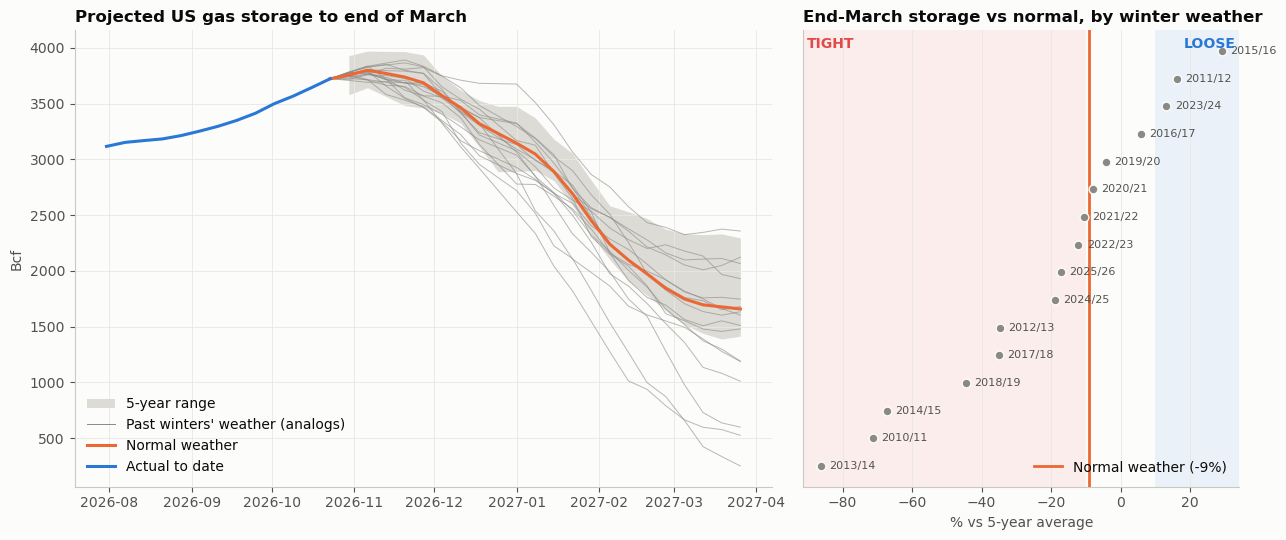

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1.6, 1]})

# Left: projected storage paths
hist = df.loc[asof - pd.Timedelta(weeks=12):asof, "storage_bcf"]
band = pd.DataFrame({d: [lvl_by_iso.get((iso_key(d)[0] - k, iso_key(d)[1]), np.nan) for k in range(1, 6)] for d in weeks})
ax1.fill_between(weeks, band.min(), band.max(), color=BAND, lw=0, label="5-year range")
start = pd.DataFrame({c: [df.loc[asof, "storage_bcf"]] for c in analogs}, index=[asof])
analogs_plot = pd.concat([start, analogs])  # join projections onto the last actual point
normal_plot = pd.concat([pd.Series([df.loc[asof, "storage_bcf"]], index=[asof]), normal_path])
for col in analogs_plot:
    ax1.plot(analogs_plot.index, analogs_plot[col], color=GRAY, lw=0.7, alpha=0.6)
ax1.plot([], [], color=GRAY, lw=0.7, label="Past winters' weather (analogs)")
ax1.plot(normal_plot.index, normal_plot, color=ORANGE, lw=2.2, label="Normal weather")
ax1.plot(hist.index, hist, color=BLUE, lw=2.2, label="Actual to date")
ax1.set_title("Projected US gas storage to end of March")
ax1.set_ylabel("Bcf")
ax1.legend(loc="lower left")

# Right: where each analog winter ends vs the thresholds
order = end_dev.sort_values()
y = np.arange(len(order))
lo = min(order.min(), TIGHT) - 5
hi = max(order.max(), LOOSE) + 5
ax2.axvspan(lo, TIGHT, color=RED, alpha=0.08, lw=0)
ax2.axvspan(LOOSE, hi, color=BLUE, alpha=0.08, lw=0)
ax2.scatter(order, y, s=40, color=GRAY, ec="#fcfcfb", lw=1, zorder=3)
for yi, (label, v) in zip(y, order.items()):
    ax2.annotate(label, (v, yi), xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color=INK2)
ax2.axvline(normal_dev, color=ORANGE, lw=2, label=f"Normal weather ({normal_dev:+.0f}%)")
ax2.text(lo + 1, len(order) - 0.5, "TIGHT", color=RED, fontweight="bold", va="top")
ax2.text(hi - 1, len(order) - 0.5, "LOOSE", color=BLUE, fontweight="bold", va="top", ha="right")
ax2.set_xlim(lo, hi)
ax2.set_yticks([])
ax2.grid(axis="y", visible=False)
ax2.set_title("End-March storage vs normal, by winter weather")
ax2.set_xlabel("% vs 5-year average")
ax2.legend(loc="lower right")
fig.tight_layout()
save(fig, "11_winter_outlook")
plt.show()

## 4. Is the price already reflecting it?
A tight outlook is only an opportunity if the price hasn't already moved up to reflect it. The code compares today's price with **past Henry Hub prices in weeks when storage was in the same state** (Tight, Normal or Loose, using actual storage deviation):
- **Below the 25th percentile = cheap**
- **Above the 75th percentile = expensive**
- **Otherwise = fair**

### The decision table

| Projected storage | Price cheap | Price fair | Price expensive |
|---|---|---|---|
| **Tight** (< -10%) | Bullish skew | Bullish skew | Priced in |
| **Normal** (±10%) | No edge | No edge | No edge |
| **Loose** (> +10%) | Priced in | Bearish skew | Bearish skew |

- **Bullish skew:** storage points to upside spike risk, and the price hasn't caught up. This is the case for considering a long position with a defined stop.
- **Bearish skew:** plenty of gas and the price is still not low. This is the case for a short, or for avoiding longs.
- **No edge / priced in:** weather will decide, or the market already agrees with you. Stay flat or trade small.

In [7]:
def price_level(price, st, before):
    """Percentile of `price` among past weekly prices (before `before`) when storage was in state `st`."""
    past = storage.loc[:before - pd.Timedelta(days=1), ["deviation_pct", "henry_hub"]].dropna()
    same = past.loc[past["deviation_pct"].apply(state) == st, "henry_hub"]
    if len(same) < 26:
        return np.nan, "fair"
    pct = (same < price).mean()
    return pct, "cheap" if pct < 0.25 else "expensive" if pct > 0.75 else "fair"


def verdict(st, level):
    if st == "Tight":
        return "Priced in" if level == "expensive" else "Bullish skew"
    if st == "Loose":
        return "Priced in" if level == "cheap" else "Bearish skew"
    return "No edge"


price_now = prices["henry_hub"].iloc[-1]
st_now = state(normal_dev)
pct_now, level_now = price_level(price_now, st_now, prices.index[-1])
v_now = verdict(st_now, level_now)

same_state = storage.loc[storage["deviation_pct"].apply(state) == st_now, "henry_hub"].dropna()
print(f"Henry Hub {price_now:.2f} $/MMBtu on {prices.index[-1].date()}")
print(f"Projected storage state (normal weather): {st_now}")
print(f"Past prices in {st_now} weeks: 25th pct ${same_state.quantile(0.25):.2f}, median ${same_state.median():.2f}, "
      f"75th pct ${same_state.quantile(0.75):.2f} -> today is at the {pct_now:.0%} percentile = {level_now}")
print(f"\nVERDICT: {v_now}")

Henry Hub 2.90 $/MMBtu on 2026-10-30
Projected storage state (normal weather): Normal
Past prices in Normal weeks: 25th pct $2.80, median $3.33, 75th pct $4.04 -> today is at the 43% percentile = fair

VERDICT: No edge


## 5. Would this rule have worked? Backtest on past winters
Every week from November to February, for winters 2015/16 to 2025/26, the code computes the signal using **only data available at that time**: the model fit, the normal weather, the price percentiles. It then measures what a long gas position entered at that Thursday's close would have returned **by the end of March**.

Returns are **roll-adjusted**: the price jump when the continuous series switches contracts is removed, because a CFD holder doesn't earn it. This roughly matches what a CFD position held through the winter would have experienced, before spreads and overnight funding.

**How to read it:** a good rule shows positive returns after *Bullish skew* signals and negative returns after *Bearish skew* signals. Watch the **number of winters**: weekly signals within one winter are highly correlated, so the real sample size is the number of winters, not the number of weeks.

In [8]:
r = np.log(prices["henry_hub"]).diff()
_, roll_days = expiry_and_roll_days(r.dropna().index)
cum = r.where(~r.index.isin(roll_days), 0).fillna(0).cumsum()  # roll-adjusted cumulative log return

signals = []
for asof_w in df.loc["2015-10-01":"2026-03-01"].index:
    if asof_w.month not in (11, 12, 1, 2):
        continue
    entry = df.loc[asof_w, "report_date"]
    exit_day = cum.loc[:season_end(asof_w) + pd.Timedelta(days=6)].index[-1]  # last trading day of March
    if entry > cum.index[-1] or exit_day <= entry:
        continue
    weeks_w = future_weeks(asof_w)
    beta_w, adj_w = fit_sensitivity(asof_w)
    end_level = project_path(asof_w, weeks_w, beta_w, adj_w)[-1] if len(weeks_w) else df.loc[asof_w, "storage_bcf"]
    dev = deviation_pct(end_level, season_end(asof_w))
    entry_px = prices["henry_hub"].asof(entry)
    st = state(dev)
    pct, level = price_level(entry_px, st, entry)
    signals.append({
        "asof": asof_w, "winter": f"{season_end(asof_w).year - 1}/{str(season_end(asof_w).year)[2:]}",
        "proj_dev_pct": dev, "state": st, "price": entry_px, "price_level": level, "verdict": verdict(st, level),
        "fwd_return_pct": np.expm1(cum.asof(exit_day) - cum.asof(entry)) * 100,  # simple % return, as a CFD account shows
    })
signals = pd.DataFrame(signals).set_index("asof")


def summarise(g):
    return pd.Series({"weeks": len(g), "winters": g["winter"].nunique(),
                      "avg return to end-Mar (%)": g["fwd_return_pct"].mean(),
                      "median (%)": g["fwd_return_pct"].median(), "% positive": (g["fwd_return_pct"] > 0).mean() * 100})


table = signals.groupby("verdict").apply(summarise)
table.loc["All winter weeks (always long)"] = summarise(signals)
table.round(1)

,weeks,winters,avg return to end-Mar (%),median (%),% positive
verdict,,,,,
Bearish skew,50.0,7.0,-17.7,-24.4,20.0
Bullish skew,30.0,6.0,-5.5,-4.8,30.0
No edge,89.0,11.0,13.7,6.8,64.0
Priced in,20.0,4.0,-8.9,-14.7,25.0
All winter weeks (always long),189.0,11.0,-0.1,-4.8,42.9


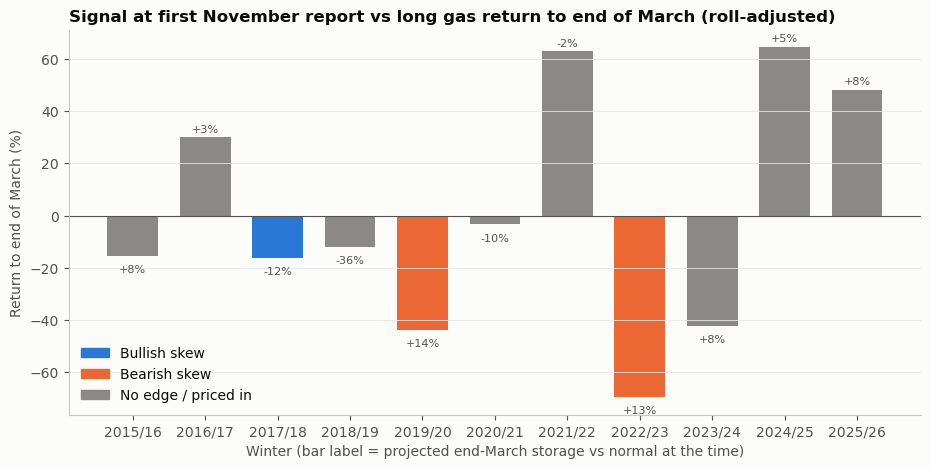

,proj_dev_pct,state,price,price_level,verdict,fwd_return_pct
winter,,,,,,
2015/16,8.4,Normal,2.3,cheap,No edge,-15.4
2016/17,3.3,Normal,2.6,fair,No edge,29.9
2017/18,-11.5,Tight,3.2,fair,Bullish skew,-16.2
2018/19,-35.7,Tight,3.5,expensive,Priced in,-12.0
2019/20,14.2,Loose,2.8,fair,Bearish skew,-43.7
2020/21,-9.8,Normal,3.0,expensive,No edge,-3.4
2021/22,-2.5,Normal,5.1,expensive,No edge,62.8
2022/23,12.9,Loose,6.2,expensive,Bearish skew,-69.5
2023/24,8.2,Normal,3.0,fair,No edge,-42.3


In [9]:
first = signals.groupby("winter").head(1).set_index("winter")  # one signal per winter: first November report
colors = {"Bullish skew": BLUE, "Bearish skew": ORANGE, "No edge": GRAY, "Priced in": GRAY}

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(first.index, first["fwd_return_pct"], color=[colors[v] for v in first["verdict"]], width=0.7)
for b, (_, row) in zip(bars, first.iterrows()):
    ax.annotate(f"{row['proj_dev_pct']:+.0f}%", (b.get_x() + b.get_width() / 2, row["fwd_return_pct"]),
                xytext=(0, 4 if row["fwd_return_pct"] >= 0 else -12), textcoords="offset points", ha="center", fontsize=8, color=INK2)
from matplotlib.patches import Patch

handles = [Patch(color=c, label=v) for v, c in [("Bullish skew", BLUE), ("Bearish skew", ORANGE), ("No edge / priced in", GRAY)]]
ax.axhline(0, color=INK2, lw=0.8)
ax.set_title("Signal at first November report vs long gas return to end of March (roll-adjusted)")
ax.set_ylabel("Return to end of March (%)")
ax.set_xlabel("Winter (bar label = projected end-March storage vs normal at the time)")
ax.grid(axis="x", visible=False)
ax.legend(handles=handles, loc="lower left")
save(fig, "12_signal_backtest_by_winter")
plt.show()

first[["proj_dev_pct", "state", "price", "price_level", "verdict", "fwd_return_pct"]].round(1)

## Findings (as of the 23 Oct 2026 report, prices to 30 Oct 2026)

### How accurate is this?
- **Next-week forecast:** the kink improves it slightly, from an average miss of 17.1 to 15.3 Bcf. The 23 Oct miss shrinks from +56 to +20 Bcf.
- **End-of-winter projection:** the average miss is **175 Bcf even with the weather that actually happened**, and **221 Bcf with normal weather**. That's about the same size as the ±10% threshold (about 183 Bcf), so a projection near a threshold could easily land on either side.
- **The rule backtest (11 winters):**

| Signal | Winters | Avg return of a long to end-March | Weeks where price rose |
|---|---|---|---|
| **Bearish skew** (loose storage, price not cheap) | 7 | **-17.7%** | 20% |
| **Bullish skew** (tight storage, price not expensive) | 6 | -5.5% | 30% |
| No edge | 11 | +13.7% (range -42% to +64%) | 64% |
| Always long | 11 | -0.1% | 43% |

- **The bearish signal worked:** prices fell after 80% of the weekly signals, including -44% in 2019/20 and -70% in 2022/23.
- **The bullish signal did not.** Tight storage didn't reliably lift prices, because it only leads to a spike if the winter is actually cold. This matches notebook 02: surpluses push prices down reliably, while deficits only make spikes possible.
- **"No edge" winters were a weather lottery,** with returns from -42% to +64%.
- **The sample is very small:** 7 and 6 winters, and the bearish result leans on two big crashes. The rule is consistent with the earlier notebooks but not statistically proven.

### Winter 2026/27 verdict: No edge, leaning tight
- Under normal weather, storage ends March at **-9.1% vs normal**, just 1 point inside the Normal zone.
- **62% of analog winters end Tight,** including 4 of the last 5 winters' weather. Injections are also running **3.7 Bcf/week tighter** than weather explains.
- Henry Hub at **$2.90 is fair** for this storage state (43rd percentile).

**What this means in practice:**
- **There's no long signal.** The outlook leans tight, but the backtest shows tight storage alone hasn't paid. A long position would be a bet on a cold winter, not on the storage data.
- **The setup that has worked (bearish skew) is absent.** Shorting gas into this winter would go against the fundamentals.
- **What would change the view:**
  - the projection crossing -10% while the price stays fair or cheap (a bullish skew, though historically weak);
  - mild weather forecasts pushing it towards +10% (a bearish skew, which has historically been the reliable one).

**Re-run this notebook after each Thursday report:** notebook 01 updates the data and the verdict updates with it.